# Анализ лояльности пользователей Яндекс Афиши

## Этапы выполнения проекта

### 1. Загрузка данных и их предобработка

---

**Задача 1.1:** Напишите SQL-запрос, выгружающий в датафрейм pandas необходимые данные. Используйте следующие параметры для подключения к базе данных `data-analyst-afisha`:

- **Хост** — `rc1e-oa2gp4mf9egcsq5k.mdb.yandexcloud.net`
- **База данных** — `data-analyst-afisha`
- **Порт** — `6432`
- **Аутентификация** — `Database Native`
- **Пользователь** — `praktikum_student`
- **Пароль** — `Sdf4$2;d-d30pp`

Для выгрузки используйте запрос из предыдущего урока и библиотеку SQLAlchemy.

Выгрузка из базы данных SQL должна позволить собрать следующие данные:

- `user_id` — уникальный идентификатор пользователя, совершившего заказ;
- `device_type_canonical` — тип устройства, с которого был оформлен заказ (`mobile` — мобильные устройства, `desktop` — стационарные);
- `order_id` — уникальный идентификатор заказа;
- `order_dt` — дата создания заказа (используйте данные `created_dt_msk`);
- `order_ts` — дата и время создания заказа (используйте данные `created_ts_msk`);
- `currency_code` — валюта оплаты;
- `revenue` — выручка от заказа;
- `tickets_count` — количество купленных билетов;
- `days_since_prev` — количество дней от предыдущей покупки пользователя, для пользователей с одной покупкой — значение пропущено;
- `event_id` — уникальный идентификатор мероприятия;
- `service_name` — название билетного оператора;
- `event_type_main` — основной тип мероприятия (театральная постановка, концерт и так далее);
- `region_name` — название региона, в котором прошло мероприятие;
- `city_name` — название города, в котором прошло мероприятие.

---


In [1]:
# Используйте ячейки типа Code для вашего кода,
# а ячейки типа Markdown для комментариев и выводов

In [2]:
# При необходимости добавляйте новые ячейки для кода или текста

In [2]:
!pip install sqlalchemy
%pip install psycopg2-binary
%pip install phik
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import os
from phik import phik_matrix
from sqlalchemy import create_engine
from dotenv import load_dotenv
from sqlalchemy import create_engine
load_dotenv()
db_config = {
    'user': os.getenv('DB_USER'),
    'pwd': os.getenv('DB_PASSWORD'),
    'host': os.getenv('DB_HOST'),
    'port': os.getenv('DB_PORT'),
    'db': os.getenv('DB_NAME')
}

connection_string = 'postgresql+psycopg2://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
)

engine = create_engine(connection_string)
engine = create_engine(connection_string)
query = '''
 WITH set_config_precode AS (
  SELECT set_config('synchronize_seqscans', 'off', true)
)
-- Напишите ваш запрос ниже
SELECT 
    user_id,
    device_type_canonical,
    order_id,
    created_dt_msk AS order_dt,
    created_ts_msk AS order_ts,
    currency_code,
    revenue,
    tickets_count,
    (created_dt_msk::date - LAG(created_dt_msk::date) OVER (
        PARTITION BY user_id 
        ORDER BY created_dt_msk
    )) AS days_since_prev,
    p.event_id,
    e.event_name_code AS event_name,
    p.service_name,
    e.event_type_main,
    r.region_name,
    c.city_name
FROM afisha.purchases AS p
LEFT JOIN  afisha.events AS e ON p.event_id = e.event_id
LEFT JOIN  afisha.city AS c ON e.city_id = c.city_id
LEFT JOIN  afisha.regions AS r ON c.region_id = r.region_id
WHERE device_type_canonical IN ('mobile', 'desktop') AND event_type_main NOT IN ('фильм')
ORDER BY user_id
'''


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [4]:
df = pd.read_sql_query(query, con=engine)

---

**Задача 1.2:** Изучите общую информацию о выгруженных данных. Оцените корректность выгрузки и объём полученных данных.

Предположите, какие шаги необходимо сделать на стадии предобработки данных — например, скорректировать типы данных.

Зафиксируйте основную информацию о данных в кратком промежуточном выводе.

---

Выведем первые пять строк датасета на экран и информацию о нем в целом. Так мы сможем оценить корректо ли выгрузились данные, увидим количество строк, их типы, и пропуски.

In [5]:
display(df.head())
df.info()

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,service_name,event_type_main,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,Край билетов,театр,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,Мой билет,выставки,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,За билетом!,другое,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,Лови билет!,другое,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,Билеты без проблем,стендап,Озернинский край,Родниковецк


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  service_name           290611 non-null  object        
 12  event_type_main        290611 non-null  obje

Датасет содержит 15 столбцов и 290611 строку в которых представлена информация о заказах Яндекс Афиши: номер заказа, уникальный идентификационный номер пользователя, тип устройства с которого был совершен заказ, дата и время создания заказа по московскому времени, валюта оплаты, выручка от заказа, количество купленных билетов, количество дней между последней и предыдущей покупкой, уникальный идентификатор мероприятия, название мероприятия, название билетного оператора, тип мероприятия, название региона и города в котором проходило пероприятие

После первичного анализа данных можно сделать следующие выводы:
- названия столбцов выглядят корректно.
- типы данных выглядят корректно.
- пропуски содержатся в столбце days_since_prev. Это нормально, ведь не у каждого покупателя есть предыдущая покупка. Однако следует проверить другие значения-индикаторы, которые могут говорить об отсутствии данных.
- значения в столбцах соответствуют своему описанию
Вероятно можно оптимизаровать размерность в столбцах order_id, revenue, tickets_count, days_since_prev, event_id.
- в датасете два вида валюты. логично будет привести суммы к рублю.

---

###  2. Предобработка данных

Выполните все стандартные действия по предобработке данных:

---

**Задача 2.1:** Данные о выручке сервиса представлены в российских рублях и казахстанских тенге. Приведите выручку к единой валюте — российскому рублю.

Для этого используйте датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю за 2024 год — `final_tickets_tenge_df.csv`. Его можно загрузить по пути `https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')`

Значения в рублях представлено для 100 тенге.

Результаты преобразования сохраните в новый столбец `revenue_rub`.

---


Прочитаем датасет с курсами тенге и запишем в переменную. Далее посмотрим на первые 5 строк данных и выведем информацию о них. Для того чтобы перевести выручку к единой валюте необходимо объединить оба датасета. Сделать это можно по дате.
Тип данных в датасете tenge_df является object. Необходимо привести его к типу datetime64.

In [6]:
tenge_df = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')
display(tenge_df.head())
tenge_df.info()
tenge_df['data']=pd.to_datetime(tenge_df['data'])

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


Далее объединяем датасеты. Следом расчитываем сумму в рублях для заказов в тенге.

In [7]:
df_merged=df.merge(
    tenge_df,
    left_on='order_dt',
    right_on='data',
    how='left')
#np.where(условие, знач.если.истина, знач.если.ложь)
df_merged['revenue_rub'] = np.where(
    df_merged['currency_code']=='kzt',
    df_merged['revenue']*df_merged['curs']/df_merged['nominal'],
    df_merged['revenue']
)

In [8]:
display(df_merged[['currency_code','revenue', 'curs', 'nominal', 'revenue_rub']].head())
df_merged['revenue_rub'].isna().sum()

,currency_code,revenue,curs,nominal,revenue_rub
0,rub,1521.94,18.6972,100,1521.94
1,rub,289.45,18.3419,100,289.45
2,rub,1258.57,19.6475,100,1258.57
3,rub,8.49,18.5010,100,8.49
4,rub,1390.41,19.6648,100,1390.41


0

In [9]:
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 290611 entries, 0 to 290610
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  service_name           290611 non-null  object        
 12  event_type_main        290611 non-null  obje

---

**Задача 2.2:**

- Проверьте данные на пропущенные значения. Если выгрузка из SQL была успешной, то пропуски должны быть только в столбце `days_since_prev`.
- Преобразуйте типы данных в некоторых столбцах, если это необходимо. Обратите внимание на данные с датой и временем, а также на числовые данные, размерность которых можно сократить.
- Изучите значения в ключевых столбцах. Обработайте ошибки, если обнаружите их.
    - Проверьте, какие категории указаны в столбцах с номинальными данными. Есть ли среди категорий такие, что обозначают пропуски в данных или отсутствие информации? Проведите нормализацию данных, если это необходимо.
    - Проверьте распределение численных данных и наличие в них выбросов. Для этого используйте статистические показатели, гистограммы распределения значений или диаграммы размаха.
        
        Важные показатели в рамках поставленной задачи — это выручка с заказа (`revenue_rub`) и количество билетов в заказе (`tickets_count`), поэтому в первую очередь проверьте данные в этих столбцах.
        
        Если обнаружите выбросы в поле `revenue_rub`, то отфильтруйте значения по 99 перцентилю.

После предобработки проверьте, были ли отфильтрованы данные. Если были, то оцените, в каком объёме. Сформулируйте промежуточный вывод, зафиксировав основные действия и описания новых столбцов.

---

Проверим данные на пропуски.


In [10]:
result_df = pd.DataFrame({ 
    'Количество пропусков': df_merged.isna().sum(),
    'Процент пропусков': df_merged.isna().mean() * 100
}).sort_values('Процент пропусков')
result_df.style.background_gradient(
    subset=['Процент пропусков'], cmap='YlOrRd', low=0.2, high=0.8
).format({'Количество пропусков': '{:.0f}', 'Процент пропусков': '{:.1f}%'})


,Количество пропусков,Процент пропусков
user_id,0,0.0%
curs,0,0.0%
nominal,0,0.0%
data,0,0.0%
city_name,0,0.0%
region_name,0,0.0%
event_type_main,0,0.0%
service_name,0,0.0%
event_name,0,0.0%
event_id,0,0.0%


Видим, что явные пропуски имеются только в столбце days_since_prev. Они связаны с тем, что не у кажого покупателя была предыдущая покупка. Следующим шагом - оптимизируем размерность в столбцах order_id, revenue, tickets_count, days_since_prev, event_id.

In [11]:
#Переводим int64 у order_id в int32
df_merged['order_id']= pd.to_numeric(df_merged['order_id'], downcast='integer')
print(df_merged['order_id'].dtype)
#Переводим float64 у revenue в int32
df_merged['revenue']= pd.to_numeric(df_merged['revenue'], downcast='float')
print(df_merged['revenue'].dtype)

#Переводим int64 у tickets_count в int8
df_merged['tickets_count']= pd.to_numeric(df_merged['tickets_count'], downcast='integer')
print(df_merged['tickets_count'].dtype)

#Переводим float64 у days_since_prev в float32
df_merged['days_since_prev']= pd.to_numeric(df_merged['days_since_prev'], downcast='float')
print(df_merged['days_since_prev'].dtype)

#Переводим int64 у event_id в int32
df_merged['event_id']= pd.to_numeric(df_merged['event_id'], downcast='integer')
print(df_merged['event_id'].dtype)

#Оставляем только дату в формате datetime64[ns]
df_merged['order_dt'] = df_merged['order_dt'].dt.normalize()

int32
float32
int8
float32
int32


Изучим данные столбцов и проверим неявные и явные дубликаты.

In [12]:
df_merged.duplicated().sum()

0

Явные дубликаты в датафрейме не обнаружены. 

In [13]:
for column in ['device_type_canonical', 'currency_code', 'tickets_count', 'event_name', 'service_name', 'event_type_main', 'region_name', 'city_name']:
    print (f'Уникальные значения в столбце {column}:')
    print(df_merged[column].sort_values().unique())
    print() 

Уникальные значения в столбце device_type_canonical:
['desktop' 'mobile']

Уникальные значения в столбце currency_code:
['kzt' 'rub']

Уникальные значения в столбце tickets_count:
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 17 19 27 30 37 47 57]

Уникальные значения в столбце event_name:
['000a9c8d-65bb-4178-a5a8-9ddc1f3bf71e'
 '0015b11d-a3e0-4656-887a-383450a9b313'
 '00298e1a-ae90-482b-819d-ba88ceff59b0' ...
 'fff20f2b-de72-451a-8168-b765352e502c'
 'fff68929-41eb-4dd7-90bf-76d3ae8b652f'
 'fffd87ef-5469-4684-af21-4f9b86a13189']

Уникальные значения в столбце service_name:
['Crazy ticket!' 'Show_ticket' 'Билет по телефону' 'Билеты без проблем'
 'Билеты в интернете' 'Билеты в руки' 'Быстробилет' 'Быстрый кассир'
 'Весь в билетах' 'Восьмёрка' 'Вперёд!' 'Выступления.ру'
 'Городской дом культуры' 'Дом культуры' 'Дырокол' 'За билетом!'
 'Зе Бест!' 'КарандашРУ' 'Кино билет' 'Край билетов' 'Лимоны'
 'Лови билет!' 'Лучшие билеты' 'Мир касс' 'Мой билет' 'Облачко'
 'Прачечная' 'Радио ticket' 'Р

В результате кода видим, что ни в одном из столбцов датафрейма нет явных и неявных дубликатов.

Теперь проверим данные на выбросы. Основные столбцы по которым они могут быть  revenue, tickets_count, days_since_prev, revenue_rub.

In [14]:
display(df_merged['revenue'].describe())
display(df_merged['tickets_count'].describe())
display(df_merged['days_since_prev'].describe())
display(df_merged['revenue_rub'].describe())

count    290611.000000
mean        625.584412
std        1227.693115
min         -90.760002
25%         116.849998
50%         356.010010
75%         810.130005
max       81174.539062
Name: revenue, dtype: float64

count    290611.000000
mean          2.754311
std           1.170620
min           1.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          57.000000
Name: tickets_count, dtype: float64

count    268678.000000
mean          3.222381
std          11.350510
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max         148.000000
Name: days_since_prev, dtype: float64

count    290611.000000
mean        555.571987
std         875.498172
min         -90.760000
25%         113.970000
50%         351.140000
75%         802.050000
max       81174.540000
Name: revenue_rub, dtype: float64

Столбцы revenue и revenue_rub по сути содержат одинаковый тип информации. В revenue суммы в рублях и тенге, а в revenue_rub суммы которые ранее были в тенге переведены в рубли. В столбцах имеется высокое стандартное отклонение. В revenue_rub среднее равно 556, а отклонение - 875. В столбце days_since_prev среднее равно 3,2 а отклонение 11,35. 
Следует в целом больше опираться на медианну т.к. она отражает более реальную картину. В revenue_rub она составляет 351, а days_since_prev - 0.
В days_since_prev можем предположить, что пользователи покупают билеты в один и тот же день несколько раз.
В tickets_count разброс значений среднего, отклонения и медины незначительный. 


<AxesSubplot:>

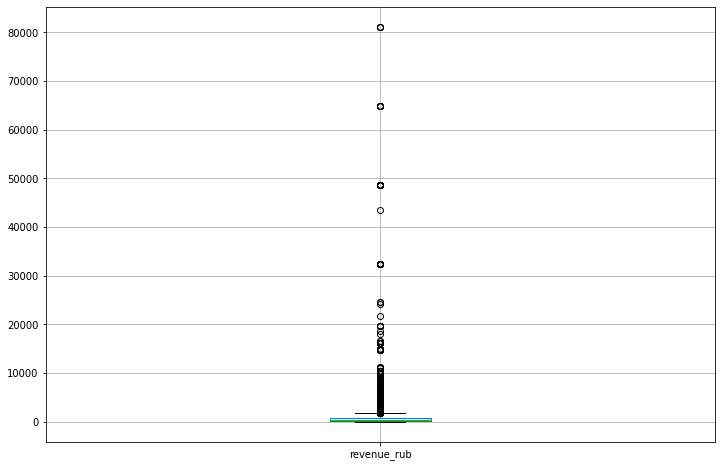

In [15]:
df_merged.boxplot(
column='revenue_rub', 
figsize=(12, 8))

df_merged.boxplot(
column='days_since_prev', 
figsize=(12, 8)

<AxesSubplot:>

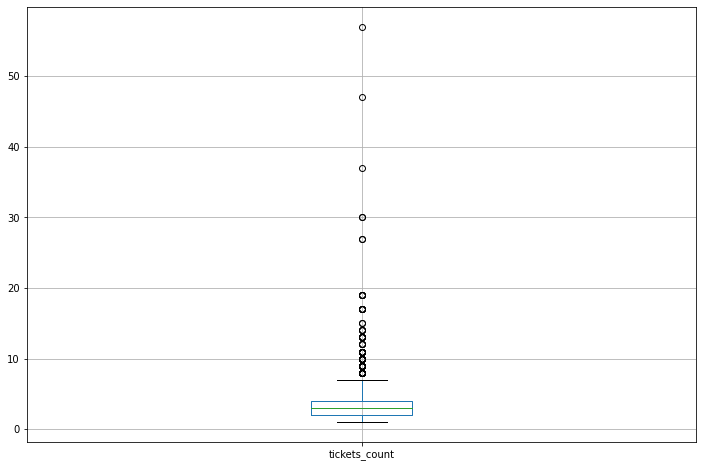

In [16]:
df_merged.boxplot(
column='tickets_count', 
figsize=(12, 8))

<AxesSubplot:>

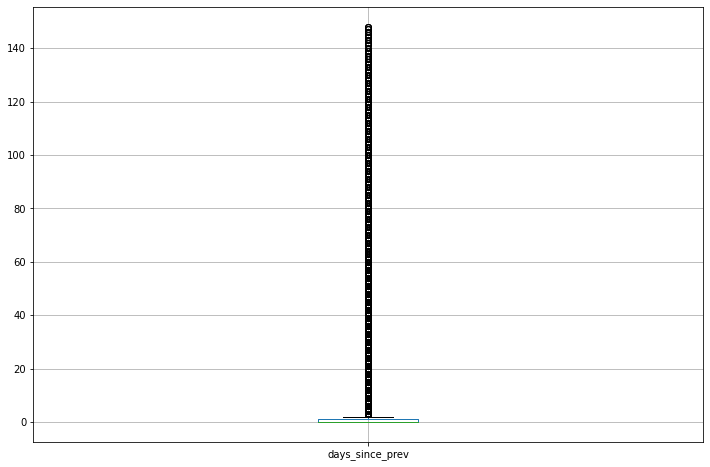

In [17]:
df_merged.boxplot(
column='days_since_prev', 
figsize=(12, 8))

На каждом из графиков усы тянутся вверх. В revenue_rub и revenue есть аномали. Это отрицательная стоимость равная - 90,76. Возможно это возврат средств или что-то, что пока сложно объяснить.

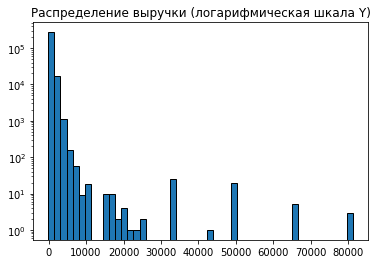

In [18]:
plt.hist(df_merged['revenue_rub'].dropna(), bins=50, log=True, edgecolor='black')
plt.title('Распределение выручки (логарифмическая шкала Y)')
plt.show()

В гистограмме выше видим, что график имеет просторонюю асимметрию. Но большая часть чеков сосредоточена в нижнем диапазоне. Необходимо вычислить 99-й процентиль. Возможно большие суммы не являются ошибками. Проверю к какой из категорий они относятся. 

In [19]:
#99-й процентиль
q99 = df_merged['revenue_rub'].quantile(0.99)

#датафрейм только с выбросами
outliers_df = df_merged[df_merged['revenue_rub'] > q99]

#датафрейм только c 99-м процентиль
df_without_outliers = df_merged[df_merged['revenue_rub'] <= q99]
#общее кол-во билетов в выбросах
tickets_in_outliers = outliers_df['tickets_count'].sum()


#группировка выбросов по категориям, суммируем билеты и считаем долю
tickets_by_category = outliers_df.groupby('event_type_main').agg(
    orders=('revenue_rub', 'count'),          # количество заказов
    total_tickets=('tickets_count', 'sum')    # суммарное количество билетов
).sort_values(by='total_tickets', ascending=False)

tickets_by_category['share_%'] = (tickets_by_category['total_tickets'] / 
tickets_in_outliers) * 100

print(tickets_by_category)
print(" ")

print(f'Количество билетов в выбросах: {tickets_in_outliers}')

print(" ")
# Среднее и максимальное количество билетов в "нормальных" заказах и в выбросах
print('Среднее кол-во билетов в обычных заказах:', df_without_outliers['tickets_count'].mean())
print('Среднее кол-во билетов в выбросах:', outliers_df['tickets_count'].mean())

                 orders  total_tickets    share_%
event_type_main                                  
концерты           1809         7571.0  64.395679
театр               593         2326.0  19.783958
другое              261         1195.0  10.164158
стендап             121          492.0   4.184741
ёлки                 21          105.0   0.893085
спорт                19           65.0   0.552862
выставки              1            3.0   0.025517
 
Количество билетов в выбросах: 11757
 
Среднее кол-во билетов в обычных заказах: 2.7404946731251694
Среднее кол-во билетов в выбросах: 4.161769911504424


Был проведен анализ заказов с высокой выручкой. Основная доля билетов в таких заказах приходится на на концерты (64,4%) и театр (19,8%). Среднее количество билетов в заказах, превышающих 99-й процентиль выручки, составляет 4,16, а в остальных заказах — 2,74.

In [20]:
# исходное кол-во строк
initial_rows = len(df_merged)

#оставляем в датасете только 99-й процентиль
df_merged = df_merged[df_merged['revenue_rub'] <= q99]


#кол-во отфильтрованных данных
final_rows = len(df_merged)
removed_rows = initial_rows - final_rows
removed_share = (removed_rows / initial_rows)*100

print(f"Удалено строк: {removed_rows} ({removed_share:.2f}% от исходного объёма)")
print(f"Осталось строк: {final_rows}")

Удалено строк: 2825 (0.97% от исходного объёма)
Осталось строк: 287786


Для анализа распределения выручки был определён 99-й процентиль, на основании которого выявлены и отфильтрованы аномально высокие значения. Для оценки объёма фильтрации были выделены заказы, превышающие 99-й процентиль. Их количество составило 2 825 наблюдений, или 0,97% исходного датасета. В результате фильтрации размер датасета сократился с 290611 до 287786 строк. Таким образом было удалено менее 1% исходных данных.

---

### 3. Создание профиля пользователя

В будущем отдел маркетинга планирует создать модель для прогнозирования возврата пользователей. Поэтому сейчас они просят вас построить агрегированные признаки, описывающие поведение и профиль каждого пользователя.

---

**Задача 3.1.** Постройте профиль пользователя — для каждого пользователя найдите:

- дату первого и последнего заказа;
- устройство, с которого был сделан первый заказ;
- регион, в котором был сделан первый заказ;
- билетного партнёра, к которому обращались при первом заказе;
- жанр первого посещённого мероприятия (используйте поле `event_type_main`);
- общее количество заказов;
- средняя выручка с одного заказа в рублях;
- среднее количество билетов в заказе;
- среднее время между заказами.

После этого добавьте два бинарных признака:

- `is_two` — совершил ли пользователь 2 и более заказа;
- `is_five` — совершил ли пользователь 5 и более заказов.

**Рекомендация:** перед тем как строить профиль, отсортируйте данные по времени совершения заказа.

---


In [21]:
#сортируем данные по пользователю и времени заказа.
df_sorted = df_merged.sort_values(['user_id', 'order_ts'])

#пересчитываем интервалы между заказами из-за убраного 1% 
df_sorted['days_between_orders'] = (
    df_sorted.groupby('user_id')['order_dt'].diff().dt.days)
#строим профиль
profile= df_sorted.groupby('user_id').agg(
    first_order_date=('order_dt', 'first'),
    last_order_date=('order_dt', 'last'),
    first_device=('device_type_canonical', 'first'),
    first_region=('region_name', 'first'),
    first_service=('service_name', 'first'),
    first_event_type=('event_type_main', 'first'),
    total_orders=('order_id', 'count'),
    avg_revenue=('revenue_rub', 'mean'),
    avg_tickets=('tickets_count', 'mean'),
    avg_days_between=('days_between_orders', 'mean')
).reset_index()

#создаем бинарные признаки
profile['is_two'] = (profile['total_orders'] >= 2).astype(int)
profile['is_five'] = (profile['total_orders'] >= 5).astype(int)

print(profile.head())

           user_id first_order_date last_order_date first_device  \
0  0002849b70a3ce2       2024-08-20      2024-08-20       mobile   
1  0005ca5e93f2cf4       2024-07-23      2024-10-06       mobile   
2  000898990054619       2024-07-13      2024-10-23       mobile   
3  00096d1f542ab2b       2024-08-15      2024-08-15      desktop   
4  000a55a418c128c       2024-09-29      2024-10-15       mobile   

           first_region  first_service first_event_type  total_orders  \
0    Каменевский регион   Край билетов            театр             1   
1    Каменевский регион      Мой билет         выставки             2   
2  Североярская область    Лови билет!           другое             3   
3    Каменевский регион   Край билетов            театр             1   
4      Поленовский край  Лучшие билеты            театр             2   

   avg_revenue  avg_tickets  avg_days_between  is_two  is_five  
0  1521.940000     4.000000               NaN       0        0  
1   774.010000     3.0

---

**Задача 3.2.** Прежде чем проводить исследовательский анализ данных и делать выводы, важно понять, с какими данными вы работаете: насколько они репрезентативны и нет ли в них аномалий.

Используя данные о профилях пользователей, рассчитайте:

- общее число пользователей в выборке;
- среднюю выручку с одного заказа;
- долю пользователей, совершивших 2 и более заказа;
- долю пользователей, совершивших 5 и более заказов.

Также изучите статистические показатели:

- по общему числу заказов;
- по среднему числу билетов в заказе;
- по среднему количеству дней между покупками.

По результатам оцените данные: достаточно ли их по объёму, есть ли аномальные значения в данных о количестве заказов и среднем количестве билетов?

Если вы найдёте аномальные значения, опишите их и примите обоснованное решение о том, как с ними поступить:

- Оставить и учитывать их при анализе?
- Отфильтровать данные по какому-то значению, например, по 95-му или 99-му перцентилю?

Если вы проведёте фильтрацию, то вычислите объём отфильтрованных данных и выведите статистические показатели по обновлённому датасету.

In [22]:
#общее число пользователей
total_users = profile.shape[0]
#средняя выручка с одного заказа
avg_revenue_simple = df_merged['revenue_rub'].mean()
#доля пользователей, совершивших 2 и более заказа
share_two = profile['is_two'].mean()
#доля пользователей, совершивших 5 и более заказа
share_five = profile['is_five'].mean()

print(f'Общее число пользователей: {total_users}')
print(f'Средняя выручка с заказа (простое среднее): {avg_revenue_simple:.2f} руб.')
print(f'Доля пользователей с 2+ заказами: {share_two:.2%}')
print(f'Доля пользователей с 5+ заказами: {share_five:.2%}')

Общее число пользователей: 21854
Средняя выручка с заказа (простое среднее): 518.03 руб.
Доля пользователей с 2+ заказами: 61.71%
Доля пользователей с 5+ заказами: 29.01%


In [23]:
#статистические показатели:
#по общему числу заказов;
#по среднему числу билетов в заказе;
#по среднему количеству дней между покупками.
stats = profile[['total_orders', 'avg_tickets', 'avg_days_between']].describe()
print(stats)

       total_orders   avg_tickets  avg_days_between
count  21854.000000  21854.000000      13486.000000
mean      13.168573      2.743129         15.877577
std      121.674800      0.913080         22.271930
min        1.000000      1.000000          0.000000
25%        1.000000      2.000000          1.000000
50%        2.000000      2.750000          8.071429
75%        5.000000      3.076923         20.500000
max    10181.000000     11.000000        148.000000


Медиана в столбце total_orders составляет всего два заказа. А 75% пользователей совершили не больше чем 5 заказов. Среднее - 13,15, а максимальное значение 10181.
Это странная ситуация. Присутствует сильная ассиметрия. Среднее существенно превышает медиану, поскольку небольшое количество пользователей с очень большим числом заказов сильно увеличивает его.

В столбце avg_tickets показатели выглядят балансно. Среднее и медиана практически совпадают, разброс значений невелик. Максимальное среднее количество билетов - 11. 

В столбце avg_days_between есть ассиметрия, где среднее превышает медиану. Возможно это вызавно пользователями, которые покупают билеты редко и с большими перерывами между покупками.
Всего количество средних дней сежду покупками 13486 потому, что у пользователей с одним заказом отсутствует интервал между заказами.

In [24]:
#выделю 99-й процентиль количества заказов
q99_orders = profile['total_orders'].quantile(0.99)

# Пользователи выше 99-го процентиля
users_outliers = profile[    profile['total_orders'] > q99_orders]


print(users_outliers[['user_id', 'total_orders']].sort_values(
    'total_orders', ascending=False
).head(10))

print('99-й процентиль:', q99_orders)
print('Количество пользователей выше 99-го процентиля:', len(users_outliers))
print('Доля пользователей выше 99-го процентиля:', 
      len(users_outliers) /len(profile))


               user_id  total_orders
981    0beb8fc0c0a9ce1         10181
2054   18e9aead0a393e7          4351
11073  8187dac4be757a0          4021
5414   3ee7dc2e115847f          3791
10810  7eb4fc207ecc10f          3710
2330   1c2a2133e1df1b4          3503
6776   4ec8f6429431987          3375
14765  ad2dc32364ed948          3249
15502  b54dd0cd81121fc          3138
17634  cdbc02c6ad8087a          3036
99-й процентиль: 152.0
Количество пользователей выше 99-го процентиля: 216
Доля пользователей выше 99-го процентиля: 0.009883774137457673


Мы видим, что хоть 216 пользователей существенно отличаются от основной массы, нельзя быть уверенными, что это ошибки данных. Да, возможно дело в выгрузке. Но можеть быть это, действительно, активные пользователи. Может с этих аккаунтов делаются корпоротивные закупки для сотрудников или что то такое. Следовательно Эти данные не стоит исключать из датасета т.к. не доказана их ошибочность.

---

### 4. Исследовательский анализ данных

Следующий этап — исследование признаков, влияющих на возврат пользователей, то есть на совершение повторного заказа. Для этого используйте профили пользователей.



#### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу

Исследуйте признаки, описывающие первый заказ пользователя, и выясните, влияют ли они на вероятность возвращения пользователя.

---

**Задача 4.1.1.** Изучите распределение пользователей по признакам.

- Сгруппируйте пользователей:
    - по типу их первого мероприятия;
    - по типу устройства, с которого совершена первая покупка;
    - по региону проведения мероприятия из первого заказа;
    - по билетному оператору, продавшему билеты на первый заказ.
- Подсчитайте общее количество пользователей в каждом сегменте и их долю в разрезе каждого признака. Сегмент — это группа пользователей, объединённых определённым признаком, то есть объединённые принадлежностью к категории. Например, все клиенты, сделавшие первый заказ с мобильного телефона, — это сегмент.
- Ответьте на вопрос: равномерно ли распределены пользователи по сегментам или есть выраженные «точки входа» — сегменты с наибольшим числом пользователей?

---


In [25]:
#признаки 
first_order_features = [
    'first_event_type', #мероприятие
    'first_device',     #устройство
    'first_region',     #регион
    'first_service']    #оператор
for col in first_order_features:
    print(f'\n Распределение по признаку: {col}')
    
    #количество пользователей в каждом сегменте
    counts = profile[col].value_counts()
    
    #дооля сегмента (в процентах)
    shares = profile[col].value_counts(normalize=True) * 100
    
    # собираем в одну таблицу
    distribution = pd.DataFrame({
        'users': counts,
        'share_%': shares.round(2)
    })
    
    print(distribution)
    


 Распределение по признаку: first_event_type
          users  share_%
концерты   9643    44.12
другое     5490    25.12
театр      4289    19.63
стендап    1118     5.12
спорт       801     3.67
выставки    418     1.91
ёлки         95     0.43

 Распределение по признаку: first_device
         users  share_%
mobile   18108    82.86
desktop   3746    17.14

 Распределение по признаку: first_region
                          users  share_%
Каменевский регион         7159    32.76
Североярская область       3799    17.38
Широковская область        1237     5.66
Озернинский край            678     3.10
Малиновоярский округ        529     2.42
...                         ...      ...
Тихогорская область           2     0.01
Светолесский край             2     0.01
Верхозёрский край             1     0.00
Яснопольский округ            1     0.00
Сосноводолинская область      1     0.00

[81 rows x 2 columns]

 Распределение по признаку: first_service
                        users  share_%
Б

Распределение пользователей неравномерное. У выборки есть особенно выраженные участки. В основном first_event_type (первом пероприятии пользователя) доминирует категория концерты - 44,12%. Почти половина пользователей впервые совершила покупку билетов именно туда. Категория другое на втором месте - 25,12%. Театр на третьем месте - 19,63%. 

Первым устройством с которого были совершены заказы у большинства пользователей это мобильный телефон (более 82%).
Пользователи распределяются по 81 региону. В основном они сосредоточены в Каменевском регионе - 7159 пользователей (32,76%), Североярской области - 3799 пользователей (17,38%), Широковской области - 1237 пользователей (5,66%). На первые два региона приходится 50,14% пользователей.
Первый билетный оператор 5223 пользователей (23,90%) - "Билеты без проблем". Дальше идут операторы: "Мой билет" 2992 (13,69%), "Лови билет!" 2848 (13,03%), "Билеты в руки"	2594 (11,87%), "Облачко" 2194 (10,04%).
Таким образом, скорее всего, привлечение пользователей преимущественно происходит через мобильный канал и определённые категории мероприятий.

---

**Задача 4.1.2.** Проанализируйте возвраты пользователей:

- Для каждого сегмента вычислите долю пользователей, совершивших два и более заказа.
- Визуализируйте результат подходящим графиком. Если сегментов слишком много, то поместите на график только 10 сегментов с наибольшим количеством пользователей. Такое возможно с сегментами по региону и по билетному оператору.
- Ответьте на вопросы:
    - Какие сегменты пользователей чаще возвращаются на Яндекс Афишу?
    - Наблюдаются ли успешные «точки входа» — такие сегменты, в которых пользователи чаще совершают повторный заказ, чем в среднем по выборке?

При интерпретации результатов учитывайте размер сегментов: если в сегменте мало пользователей (например, десятки), то доли могут быть нестабильными и недостоверными, то есть показывать широкую вариацию значений.

---


Средняя доля пользователей с 2+ заказами по выборке: 61.71%

 users return_share_ first_event_type
  9643        62.16%         концерты
  5490        60.09%           другое
  4289        63.81%            театр
  1118        61.18%          стендап
   801        56.18%            спорт
   418        64.35%         выставки
    95        55.79%             ёлки


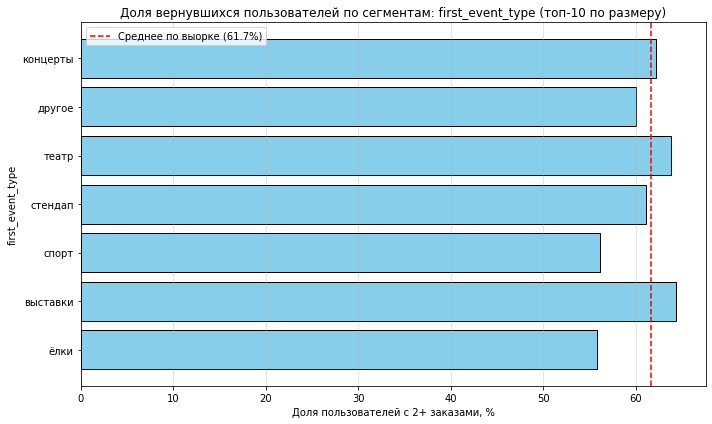

 users return_share_ first_device
 18108        61.21%       mobile
  3746        64.12%      desktop


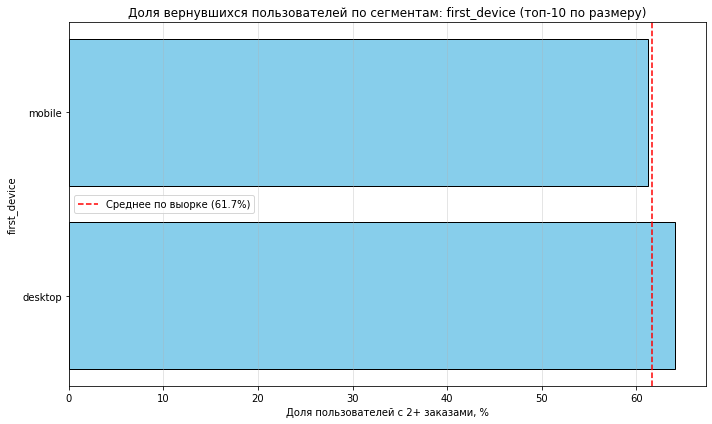

 users return_share_              first_region
  7159        62.79%        Каменевский регион
  3799        64.12%      Североярская область
  1237        64.92%       Широковская область
   678        55.46%          Озернинский край
   529        56.33%      Малиновоярский округ
   503        67.40%          Шанырский регион
   493        61.87%          Травяная область
   464        66.16%      Светополянский округ
   446        63.90%       Речиновская область
   416        59.86%       Яблоневская область
   378        59.79%         Медовская область
   378        58.20%       Верхоречная область
   358        56.15%      Лугоградская область
   333        55.86%      Серебринская область
   323        59.44%      Тепляковская область
   296        58.45% Солнечнореченская область
   286        59.44%   Солнечноземская область
   255        67.84%      Горицветская область
   219        53.88%      Глиногорская область
   219        60.27%          Зоринский регион
   214       

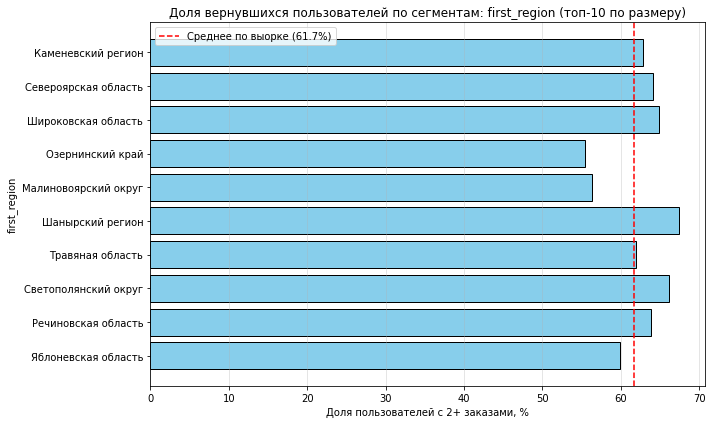

 users return_share_          first_service
  5223        60.69%     Билеты без проблем
  2992        61.16%              Мой билет
  2848        61.45%            Лови билет!
  2594        63.22%          Билеты в руки
  2194        61.58%                Облачко
  1304        63.42%         Весь в билетах
  1188        61.36%          Лучшие билеты
   588        62.93%              Прачечная
   459        65.58%           Край билетов
   358        64.80%           Дом культуры
   320        53.75%                 Яблоко
   311        60.77%            Тебе билет!
   219        59.36% Городской дом культуры
   211        64.93%               Мир касс
   203        59.11%            За билетом!
   163        66.26%            Show_ticket
   162        59.26%            Быстробилет
    96        62.50%         Выступления.ру
    86        68.60%              Восьмёрка
    61        85.25%         Быстрый кассир
    45        68.89%          Crazy ticket!
    40        85.00%            

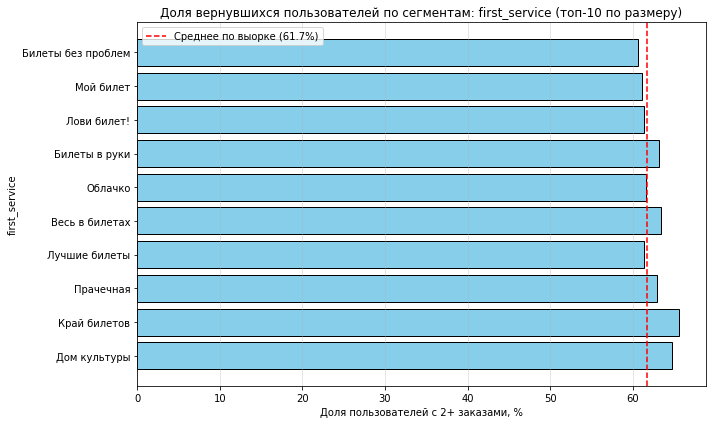

In [26]:
first_order_features = [
    'first_event_type',
    'first_device',
    'first_region',
    'first_service']
#средняя доля 
overall_share = profile['is_two'].mean()
print(f'Средняя доля пользователей с 2+ заказами по выборке: {overall_share:.2%}\n')

# cредняя доля вернувшихся по выборке
for col in first_order_features:
    segment_stats = profile.groupby(col).agg(
        users=('user_id', 'count'),
        return_share=('is_two', 'mean')).reset_index()

    segment_stats = segment_stats.sort_values('users', ascending=False)
    top10 = segment_stats.head(10).copy()
    top10['return_share_%'] = top10['return_share'] * 100
    print(segment_stats.assign(
        return_share_=segment_stats['return_share'].map('{:.2%}'.format)
    )[['users', 'return_share_', col]].to_string(index=False))

    plt.figure(figsize=(10, 6))
    plt.barh(top10[col], top10['return_share_%'], color='skyblue', edgecolor='black')
    plt.axvline(overall_share * 100, color='red', linestyle='--',
                label=f'Среднее по выорке ({overall_share:.1%})')
    plt.xlabel('Доля пользователей с 2+ заказами, %')
    plt.ylabel(col)
    plt.title(f'Доля вернувшихся пользователей по сегментам: {col} (топ-10 по размеру)')
    plt.legend()
    plt.gca().invert_yaxis()
    plt.grid(axis='x', alpha=0.4)
    plt.tight_layout()
    plt.show()
    

Наиболее высокая доля повторных покупок наблюдается среди пользователей, которые впервые посетивших выставки (64,35%) и театр (63,81%). Концерты как мы выясняли ранее самый большой сегмент и он тоже имеет большой показатель повторной покупки 62,16%. Спорт и елки имеют долю возварата меньше средней.

Пользователи которые совершили покупку с компьютера имеют более высокий процент возвращения. 64,12% против 61,21%. Но ранее мы выяснили, что основной приток пользователей обеспечивает мобильный канал. 

Среди крупнейших региональных сегментов наиболее высокая доля возвратов наблюдается в Шанырском регионе (67,40%), Светополянском округе (66,16%) и Широковской области (64,92%). Каменевский регион, несмотря на крупнейшую аудиторию, также демонстрирует возврат выше среднего (62,79%). В Озернинском крае и Малиновоярском округе доля возвратов пользователей заметно ниже среднего по выборке. В Шанырском регионе и Светополянском округе доля вернувшихся пользователей существенно выше среднего, при этом в каждом сегменте более 450 пользователей.

Наиболее высокую долю возвратов демонстрируют "Край билетов" (65,58%) и "Дом культуры" (64,80%). "Весь в билетах2 и "Билеты в руки" также имеют показатели выше среднего - 63,42% и 63,22%. Более высокая доля возвратов не обязательно связана с крупнейшими билетными операторами. Некоторые менее массовые операторы демонстрируют более высокую возвращаемость. 

---

**Задача 4.1.3.** Опираясь на выводы из задач выше, проверьте продуктовые гипотезы:

- **Гипотеза 1.** Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.
- **Гипотеза 2.** В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.

---

Гипотеза 1: Сравним спортивные мероприятия и концерты

In [27]:
sport = profile[profile['first_event_type'] == 'спорт']
concert = profile[profile['first_event_type'] == 'концерты']

n_sport = len(sport)
n_concert =  len(concert)

success_sport = sport['is_two'].sum()
success_concert = concert['is_two'].sum()

p_sport = success_sport / n_sport
p_concert = success_concert / n_concert

print(f'Спорт: {n_sport} чел., доля 2+ = {p_sport:.2%}')
print(f'Концерты: {n_concert} чел., доля 2+ = {p_concert:.2%}')
print(f'Разница (спорт − концерты): {(p_sport - p_concert)*100:+.2f}')


Спорт: 801 чел., доля 2+ = 56.18%
Концерты: 9643 чел., доля 2+ = 62.16%
Разница (спорт − концерты): -5.98


Видим, что гипотеза 1 не подтверждается т.к. пользователи, начавшие со спортивных мероприятий совершают повторный заказ реже, чем начавшие с концертов: 56.18% против 62.16% (разница 5,98). И количество пользователей сервиса в сегментах достаточно большое чтобы не считать этот разрыв случайным. 

Гипотеза 2: Стоит сравнить активные и менее активные регионы

In [28]:
region_stats = profile.groupby('first_region').agg(
    users=('user_id', 'count'),
    return_share=('is_two', 'mean')).reset_index()

#медианное количество пользователей
region_stats_clean = region_stats[region_stats['users'] >= 50]
median_users = region_stats_clean['users'].median()
print(median_users)

#делим регионы на две группы
large = region_stats_clean[region_stats_clean['users'] > median_users]
small = region_stats_clean[    region_stats_clean['users'] <= median_users]

# определяем активные и менее активные регионы
active_regions = large['first_region']
less_active_regions = small['first_region']

# возвращаемость более активных регионов
active_return = profile[profile['first_region'].isin(active_regions)]['is_two'].mean()
# возвращаемость менее активных регионов
less_active_return = profile[profile['first_region'].isin(less_active_regions)]['is_two'].mean()

print(f'Активные регионы: {active_return:.2%}')
print(f'Менее активные регионы: {less_active_return:.2%}')
print(f'Общая возвращаемость: {profile["is_two"].mean():.2%}')

205.5
Активные регионы: 62.30%
Менее активные регионы: 58.45%
Общая возвращаемость: 61.71%


В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах. В активных регионах доля пользователей с повторными заказами составила 62,30%, в менее активных — 58,45%. Но при этом разница между ними несушественная. 

---

#### 4.2. Исследование поведения пользователей через показатели выручки и состава заказа

Изучите количественные характеристики заказов пользователей, чтобы узнать среднюю выручку сервиса с заказа и количество билетов, которое пользователи обычно покупают.

Эти метрики важны не только для оценки выручки, но и для оценки вовлечённости пользователей. Возможно, пользователи с более крупными и дорогими заказами более заинтересованы в сервисе и поэтому чаще возвращаются.

---

**Задача 4.2.1.** Проследите связь между средней выручкой сервиса с заказа и повторными заказами.

- Постройте сравнительные гистограммы распределения средней выручки с билета (`avg_revenue_rub`):
    - для пользователей, совершивших один заказ;
    - для вернувшихся пользователей, совершивших 2 и более заказа.
- Ответьте на вопросы:
    - В каких диапазонах средней выручки концентрируются пользователи из каждой группы?
    - Есть ли различия между группами?

Текст на сером фоне:
    
**Рекомендация:**

1. Используйте одинаковые интервалы (`bins`) и прозрачность (`alpha`), чтобы визуально сопоставить распределения.
2. Задайте параметру `density` значение `True`, чтобы сравнивать форму распределений, даже если число пользователей в группах отличается.

---


In [29]:
#пользователи с одним заказом
one_order = profile[profile['is_two'] == 0]
returned  = profile[profile['is_two'] == 1]

print('Один заказ:')
print(one_order['avg_revenue'].describe())

print('\nПовторные заказы:')
print(returned['avg_revenue'].describe())

Один заказ:
count    8368.000000
mean      545.295642
std       519.514097
min       -10.770000
25%       132.070000
50%       378.030000
75%       830.317500
max      2628.421739
Name: avg_revenue, dtype: float64

Повторные заказы:
count    13486.000000
mean       543.841100
std        366.645729
min         -5.385000
25%        274.112500
50%        497.621965
75%        739.353324
max       2628.421739
Name: avg_revenue, dtype: float64


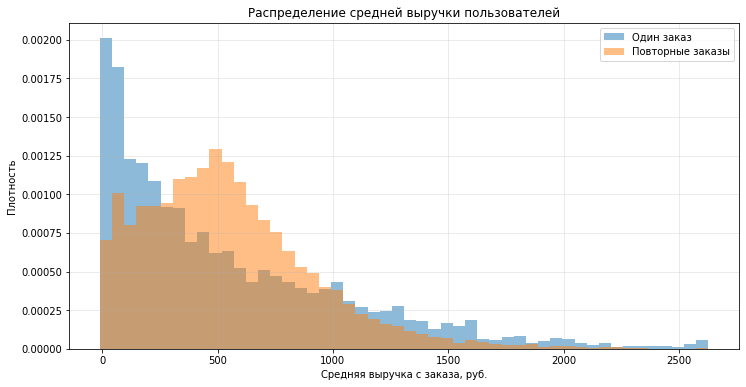

In [30]:
bins = np.linspace(
    profile['avg_revenue'].min(),
    profile['avg_revenue'].max(),
    51
)

plt.figure(figsize=(12, 6))

plt.hist(
    one_order['avg_revenue'],
    bins=bins,
    density=True,
    alpha=0.5,
    label='Один заказ'
)

plt.hist(
    returned['avg_revenue'],
    bins=bins,
    density=True,
    alpha=0.5,
    label='Повторные заказы'
)

plt.xlabel('Средняя выручка с заказа, руб.')
plt.ylabel('Плотность')
plt.title('Распределение средней выручки пользователей')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Пользователи бли разделены на две группы - совершившие один заказ (8368 человек) и совершившие два и более заказов (13486 человек). И для каждог группы построена гистограмма которая наглядно отображает распределение выручки, а также пересечение двух категорий пользователей. 

Пользователи с повторными заказами имеют более высокую медианную среднюю выручку с заказа, но распределения обеих групп заметно пересекаются.
Средняя выручка практически не различается между группами: 545,30 у пользователей с одним заказом и 543,84 у пользователей с повторными заказами.
Различия между группами заключаются в том, что выручка повторных пользователей составляет 497,62, тогда как у пользователей с одним заказом — 378,03.
На гистограмме распределение повторных пользователей имеет концентрацию в диапазоне около 400–500 рублй. У пользователей с одним заказом заметнее концентрация небольших значений выручки и более выражен разброс.


---

**Задача 4.2.2.** Сравните распределение по средней выручке с заказа в двух группах пользователей:

- совершившие 2–4 заказа;
- совершившие 5 и более заказов.

Ответьте на вопрос: есть ли различия по значению средней выручки с заказа между пользователями этих двух групп?

---


In [31]:
#пользователи с 2–4 заказами
users_2_4 = profile[
    (profile['total_orders'] >= 2) & (profile['total_orders'] <= 4)]
#пользователи с 5+ заказами
users_5_plus = profile[profile['is_five'] == 1]


print('2–4 заказа:')
print(users_2_4['avg_revenue'].describe())
print(' ')
print('5 и более заказов:')
print(users_5_plus['avg_revenue'].describe())

2–4 заказа:
count    7147.000000
mean      551.572386
std       420.197691
min        -5.385000
25%       218.428750
50%       471.266667
75%       798.550000
max      2628.421739
Name: avg_revenue, dtype: float64
 
5 и более заказов:
count    6339.000000
mean      535.124347
std       294.615103
min         0.000000
25%       336.966333
50%       513.560000
75%       690.016087
max      2299.869022
Name: avg_revenue, dtype: float64


Пользователи были разделены на две группы: совершившие 2–4 заказа (7147 человек) и 5 и более заказов (6339 человек). Средняя выручка с заказа составила 551,57 рублей в первой группе и 535,12 рублей во второй. Медианная выручка пользователей с 5 и более заказами оказалась выше - 513,56 против 471,27. 
Разница в средней выручке есть, но небольшая - 16,45 рублей.

---

**Задача 4.2.3.** Проанализируйте влияние среднего количества билетов в заказе на вероятность повторной покупки.

- Изучите распределение пользователей по среднему количеству билетов в заказе (`avg_tickets_count`) и опишите основные наблюдения.
- Разделите пользователей на несколько сегментов по среднему количеству билетов в заказе:
    - от 1 до 2 билетов;
    - от 2 до 3 билетов;
    - от 3 до 5 билетов;
    - от 5 и более билетов.
- Для каждого сегмента подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы.
- Ответьте на вопросы:
    - Как распределены пользователи по сегментам — равномерно или сконцентрировано?
    - Есть ли сегменты с аномально высокой или низкой долей повторных покупок?

---

In [32]:
profile['avg_tickets'].describe()
profile['tickets_segment'] = pd.cut(
    profile['avg_tickets'],
    bins=[1, 2, 3, 5, np.inf],
    labels=['1–2 билета', '2–3 билета', '3–5 билетов', '5+ билетов'],
    right=False)

tickets_stats = profile.groupby(
    'tickets_segment',
    observed=False).agg(
    users=('user_id', 'count'),
    return_share=('is_two', 'mean')).reset_index()

tickets_stats['users_share'] = (
    tickets_stats['users'] / tickets_stats['users'].sum() * 100)

tickets_stats['return_share_pct'] = (
    tickets_stats['return_share'] * 100)

print(tickets_stats)
print(f'Общая возвращаемость: {profile["is_two"].mean():.2%}')

  tickets_segment  users  return_share  users_share  return_share_pct
0      1–2 билета   2419      0.513022    11.068912         51.302191
1      2–3 билета   9706      0.741500    44.412922         74.150010
2     3–5 билетов   9068      0.543008    41.493548         54.300838
3      5+ билетов    661      0.187595     3.024618         18.759455
Общая возвращаемость: 61.71%


Распределение пользователей по среднему количеству билетов в заказе неравномерное. В основном большинство приходится на сегменты 2–3 билетов (44,41%) и 3–5 билетов (41,49%). Вместе это около 85,9% пользователей. На сегмент 5 и более билетов приходится лишь 3,02% пользователей.

Наибольшая доля повторных покупок наблюдается среди пользователей со средним количеством 2–3 билетов в заказе и составляет 74,15%. Это аномальный показатель. В сегментах 1–2 и 3–5 билетов показатели ниже среднего по выборке и составляют 51,3% и 54,3%. Низкая доля повторных покупок среди пользователей со средним количеством 5 и более билетов — 18,76%. Это аномально низкий процент и ниже среднего на 42,95%. 



---

#### 4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки

Изучите временные параметры, связанные с первым заказом пользователей:

- день недели первой покупки;
- время с момента первой покупки — лайфтайм;
- средний интервал между покупками пользователей с повторными заказами.

---

**Задача 4.3.1.** Проанализируйте, как день недели, в которой была совершена первая покупка, влияет на поведение пользователей.

- По данным даты первого заказа выделите день недели.
- Для каждого дня недели подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы. Результаты визуализируйте.
- Ответьте на вопрос: влияет ли день недели, в которую совершена первая покупка, на вероятность возврата клиента?

---


In [33]:
weekday_names = {
    0: 'Понедельник',
    1: 'Вторник',
    2: 'Среда',
    3: 'Четверг',
    4: 'Пятница',
    5: 'Суббота',
    6: 'Воскресенье'}

profile['first_order_date'] = pd.to_datetime(profile['first_order_date'])

profile['first_order_weekday'] = (
    profile['first_order_date'].dt.dayofweek.map(weekday_names))

weekday_stats = profile.groupby('first_order_weekday').agg(
    users=('user_id', 'count'),
    return_share=('is_two', 'mean')).reset_index()

weekday_stats['return_share_pct'] = (weekday_stats['return_share'] * 100)

weekday_order = [
    'Понедельник',
    'Вторник',
    'Среда',
    'Четверг',
    'Пятница',
    'Суббота',
    'Воскресенье']

weekday_stats['first_order_weekday'] = pd.Categorical(weekday_stats['first_order_weekday'],
    categories=weekday_order,
    ordered=True)

weekday_stats = weekday_stats.sort_values('first_order_weekday')

print(weekday_stats)


  first_order_weekday  users  return_share  return_share_pct
2         Понедельник   2943      0.632008         63.200815
1             Вторник   3189      0.620571         62.057071
4               Среда   3072      0.623698         62.369792
6             Четверг   3120      0.595192         59.519231
3             Пятница   3261      0.598589         59.858939
5             Суббота   3459      0.642382         64.238219
0         Воскресенье   2810      0.604982         60.498221


Есть небольшие различия между днями недели. Наибольшая доля повторных покупок наблюдается среди пользователей, совершивших первую покупку в субботу (64,24%), а наименьшая — в четверг (59,52%). Разница между максимальным и минимальным показателями составляет 4,72%. В понедельник доля повторных покупок также выше среднего по выборке (63,20%), тогда как в четверг и пятницу показатели ниже среднего. День недели, в которую совершена первая покупка, не влияет на вероятность возврата клиента

---

**Задача 4.3.2.** Изучите, как средний интервал между заказами влияет на удержание клиентов.

- Рассчитайте среднее время между заказами для двух групп пользователей:
    - совершившие 2–4 заказа;
    - совершившие 5 и более заказов.
- Исследуйте, как средний интервал между заказами влияет на вероятность повторного заказа, и сделайте выводы.

---


In [34]:
#разделяем на группы
users_2_4 = profile[
    (profile['total_orders'] >= 2) &
    (profile['total_orders'] <= 4)]

users_5_plus = profile[profile['total_orders'] >= 5]

#расчитываем средний интервал
print('2–4 заказа:', users_2_4['avg_days_between'].mean())
print('5 и более заказов:', users_5_plus['avg_days_between'].mean())

#сравниваем
interv = users_2_4['avg_days_between'].mean()/users_5_plus['avg_days_between'].mean()
print(f'Сравнение среднего интервала: {interv}')


2–4 заказа: 21.407210484585605
5 и более заказов: 9.643108947715302
Сравнение среднего интервала: 2.219949043472906


Средний интервал между заказами пользователей с 2–4 заказами - 21,41 дня, а среди пользователей с 5 и более заказами - 9,64 дня. Пользователи с большим количеством заказов совершают покупки в среднем примерно в 2,2 раза чаще. Это указывает на связь между высокой покупательской активностью и меньшим интервалом между заказами.


---

#### 4.4. Корреляционный анализ количества покупок и признаков пользователя

Изучите, какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок. Для этого используйте универсальный коэффициент корреляции `phi_k`, который позволяет анализировать как числовые, так и категориальные признаки.

---

**Задача 4.4.1:** Проведите корреляционный анализ:
- Рассчитайте коэффициент корреляции `phi_k` между признаками профиля пользователя и числом заказов (`total_orders`). При необходимости используйте параметр `interval_cols` для определения интервальных данных.
- Проанализируйте полученные результаты. Если полученные значения будут близки к нулю, проверьте разброс данных в `total_orders`. Такое возможно, когда в данных преобладает одно значение: в таком случае корреляционный анализ может показать отсутствие связей. Чтобы этого избежать, выделите сегменты пользователей по полю `total_orders`, а затем повторите корреляционный анализ. Выделите такие сегменты:
    - 1 заказ;
    - от 2 до 4 заказов;
    - от 5 и выше.
- Визуализируйте результат корреляции с помощью тепловой карты.
- Ответьте на вопрос: какие признаки наиболее связаны с количеством заказов?

---

In [48]:
#список признаков
list_cols = [
    'first_order_weekday',
    'first_device',
    'first_region',
    'first_service',
    'first_event_type',
    'total_orders',
    'avg_revenue',
    'avg_tickets',
    'avg_days_between']
#матрица корреляции
corr_matrix = profile[list_cols].phik_matrix(interval_cols=[
        'total_orders',
        'avg_revenue',
        'avg_tickets',
        'avg_days_between'])

corr_matrix['total_orders'].sort_values(ascending=False)
  
profile['total_orders'].value_counts().sort_index()

#сегментация пользователей
profile['orders_segment'] = pd.cut(
    profile['total_orders'],
    bins=[0, 1, 4, np.inf],
    labels=['1 заказ', '2–4 заказа', '5+ заказов'])

profile['orders_segment'].value_counts().sort_index()

phik_cols_segment = [
    'first_order_weekday',
    'first_device',
    'first_region',
    'first_service',
    'first_event_type',
    'orders_segment',
    'avg_revenue',
    'avg_tickets']
#количество пользователей в каждой группе
corr_matrix_segment = profile[phik_cols_segment].phik_matrix(interval_cols=[
        'avg_revenue','avg_tickets'])

corr_matrix_segment['orders_segment'].sort_values(ascending=False)

orders_segment         1.000000
avg_tickets            0.390477
avg_revenue            0.334764
first_region           0.125589
first_service          0.085467
first_order_weekday    0.047876
first_event_type       0.041205
first_device           0.016259
Name: orders_segment, dtype: float64

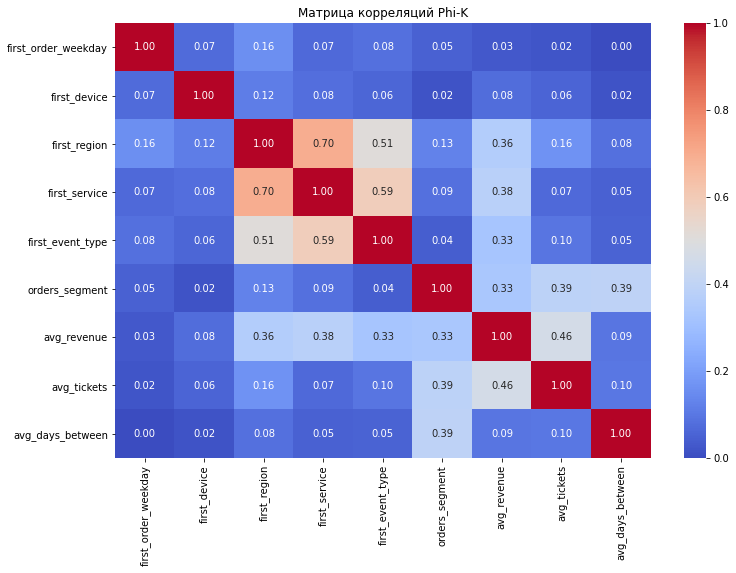

In [45]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix_segment,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=0,
    vmax=1
)

plt.title('Матрица корреляций Phi-K')
plt.show()

По результатам корреляции видно, что более выражненная связь наблюдается у у среднего количества билетов в заказе (0,39) и средней выручки (0,33). Среди характеристик первого заказа наиболее заметная, но слабая связь наблюдается с регионом (0,126).
День недели первой покупки, устройство и тип мероприятия практически не связаны с количеством заказов.

### 5. Общий вывод и рекомендации

В конце проекта напишите общий вывод и рекомендации: расскажите заказчику, на что нужно обратить внимание. В выводах кратко укажите:

- **Информацию о данных**, с которыми вы работали, и то, как они были подготовлены: например, расскажите о фильтрации данных, переводе тенге в рубли, фильтрации выбросов.
- **Основные результаты анализа.** Например, укажите:
    - Сколько пользователей в выборке? Как распределены пользователи по числу заказов? Какие ещё статистические показатели вы подсчитали важным во время изучения данных?
    - Какие признаки первого заказа связаны с возвратом пользователей?
    - Как связаны средняя выручка и количество билетов в заказе с вероятностью повторных покупок?
    - Какие временные характеристики влияют на удержание (день недели, интервалы между покупками)?
    - Какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок согласно результатам корреляционного анализа?
- Дополните выводы информацией, которая покажется вам важной и интересной. Следите за общим объёмом выводов — они должны быть компактными и ёмкими.

В конце предложите заказчику рекомендации о том, как именно действовать в его ситуации. Например, укажите, на какие сегменты пользователей стоит обратить внимание в первую очередь, а какие нуждаются в дополнительных маркетинговых усилиях.

### 6. Финализация проекта и публикация в Git

Когда вы закончите анализировать данные, оформите проект, а затем опубликуйте его.

Выполните следующие действия:

1. Создайте файл `.gitignore`. Добавьте в него все временные и чувствительные файлы, которые не должны попасть в репозиторий.
2. Сформируйте файл `requirements.txt`. Зафиксируйте все библиотеки, которые вы использовали в проекте.
3. Вынести все чувствительные данные (параметры подключения к базе) в `.env`файл.
4. Проверьте, что проект запускается и воспроизводим.
5. Загрузите проект в публичный репозиторий — например, на GitHub. Убедитесь, что все нужные файлы находятся в репозитории, исключая те, что в `.gitignore`. Ссылка на репозиторий понадобится для отправки проекта на проверку. Вставьте её в шаблон проекта в тетрадке Jupyter Notebook перед отправкой проекта на ревью.

**Вставьте ссылку на проект в этой ячейке тетрадки перед отправкой проекта на ревью.**